# Stratifying NMR Scans

`CC-BY 2026 James B. Wilson`

A sensor network consists of a grid of sensors in space.  What they record often reflects events in the whole space such as a sound, motion, light, magnetism, or other wave behavior.  Naturally these are easier to identify if we transform to wave-based coordinates, because this concentrates the diffuse spatial effects of wave patterns.  Since the point is to detect unknown frequencies, we typically bin the range of detectable frequencies, often uniformly spaced like the keys on a piano, and choose a representative frequency from each bin as the coordinate.  Extending the metaphor, we look to see which keys on the piano are played by the data.  This constitutes the [Fourier transform](https://en.wikipedia.org/wiki/Fourier_transform).  In the case of data with multiple linear axes we can consider these transformations done independently or symmetrically across the various axes.

Now one can predict the complication.  Suppose that our data represents events where different frequencies are packed together within a single bin.  These we will not be separated by the Fourier Transform and will give the impression of one overall strong signal at one frequency instead of a mixture of several separate sub-signals.  One option is to increase the resolution of our probe, by metaphor, adding black key between our white keys on our piano.  These new bins will increase the ability to separate signals but come at an engineering cost of perhaps increasing the number of sensors or their sensitivity to discern these smaller bins without altering the signal-to-noise ratio (SNR).  Notice this also tends to introduce sensitivity to new sub-frequencies most of which have nothing to do with our data in the service of separating only a few.

Dleto offers a different strategy.  By surveying the algebraic relationships of the data table, the algorithm selects the same number of bins as in the Fourier Transform but this time it creates the bins as a response to the data's shape and so it can select a few small bins and frequencies that overlap while leaving other bins wide cover the unused spectra.  In our metaphor this is the option simply return the piano you have so that it has keys that play the notes of your data instead of building a new piano that adds a bundle of unused keys simply so that it include the notes you were missing.

This lab explores this phenomena using 3D biological scanning data publically available at
[*Biological Magnetic Resonance Data Bank (BMRB)*](https://bmrb.io/).

 The specific dataset is mouse thiamine triphosphatase, BMRB entry 15063, whose summary page is https://bmrb.io/data_library/summary/?bmrbId=15063 and whose raw time-domain deposit is https://bmrb.io/ftp/pub/bmrb/entry_directories/bmr15063/timedomain_data/ . The HNCO experiment used here comes from the deposited directory https://bmrb.io/ftp/pub/bmrb/entry_directories/bmr15063/timedomain_data/hnco.fid/ . Full bibliography: BMRB. Biological Magnetic Resonance Data Bank. https://bmrb.io/ ; BMRB. “Entry 15063: Mouse thiamine triphosphatase.” https://bmrb.io/data_library/summary/?bmrbId=15063 ; BMRB. “timedomain_data/.” https://bmrb.io/ftp/pub/bmrb/entry_directories/bmr15063/timedomain_data/ ; BMRB. “hnco.fid/.” https://bmrb.io/ftp/pub/bmrb/entry_directories/bmr15063/timedomain_data/hnco.fid/ ; Wilson, James B. “Stratifying NMR Scans.” In preparation; A. M. et al. “Structural Basis for the Catalytic Mechanism of Mammalian 25-kDa Thiamine Triphosphatase.” [Journal details to be inserted if desired].


1. a tiny synthetic warm-up on a `6×6×6` tensor,
2. one real 3D HNCO band from a protein,
3. one question: **can Dleto separate close peaks from a short record when the FFT bin is too coarse?**

The intended audience is a lay reader who knows high-school chemistry: atoms have different chemical environments, NMR peaks are reported as chemical shifts, and closer peaks are harder to tell apart when the experiment is short.

## The plain-language idea

An FFT uses a fixed frequency grid.  If two true frequencies sit between the grid lines, or lie closer together than one FFT bin, a short record blurs them together.  Dleto tries to learn a better basis from the data itself.  If the signal is really a small sum of damped exponentials, the learned coordinates can be much sparser than the original tensor.

In this notebook, success means two things at once:

- the **strata** are far sparser than the original record, and
- the recovered peak positions agree with the measured reference peaks.

## Sources and attribution

- Helper code: `harmonic-retrieval/HarmonicRetrieval.jl`.
- Original published source: public BMRB entry 15063 for mouse thiamine triphosphatase, collected on a Varian 600 MHz spectrometer.
- BMRB summary page: `https://bmrb.io/data_library/summary/?bmrbId=15063`.
- Raw time-domain deposit: `https://bmrb.io/ftp/pub/bmrb/entry_directories/bmr15063/timedomain_data/`.
- Specific HNCO directory used as the upstream source: `https://bmrb.io/ftp/pub/bmrb/entry_directories/bmr15063/timedomain_data/hnco.fid/`.
- Prepared sub-band file used in this notebook: `harmonic-retrieval/data/bmr15063_hnco_band_3.56-3.68ppm.h5`.
- Preparation details: `harmonic-retrieval/data/README.md` and `harmonic-retrieval/nmr/prepare_subband3d.py`.
- Provenance note: the local HDF5 file is a prepared narrow-band extraction derived from the public BMRB deposit, not the untouched raw acquisition directory.
- Associated structure paper: “Structural Basis for the Catalytic Mechanism of Mammalian 25-kDa Thiamine Triphosphatase.”

Chemical shifts below are reported **relative to the carrier** (ppm from carrier), exactly as in the prepared dataset; they are not re-referenced to DSS.

## 1. Setting up

Run from the `labs/` folder of a clone of `OpenDleto`.  The notebook uses only packages already listed in the project.

In [113]:
using Pkg
Pkg.activate("../")
using ITensors, Plots, LinearAlgebra, Statistics, Printf, HDF5, FFTW, Random
using Dleto
include("harmonic-retrieval/HarmonicRetrieval.jl"); using .HarmonicRetrieval: fft_peaks_1d, frequency

  Activating project at `~/CODE/OpenDleto`


## 2. Synthetic example

Let's begin by making a small demonstration of a traditional Fourier Transform which tries to match the data to keys on the piano.  Then the Dleto style which uses the data to tune the piano keys.

We begin by thinking of a signal as a mix of waves that oscillate while gradually losing amplitude, known as a damped oscillator.  Here is one such component along the x-axis.

## 2.1 Damped wave forms.

If you are comfortable with damped oscillators you may skim this section which simply walks through choosing a discrete sample of a damped oscillator.  Otherwise this gives a quick demonstration.

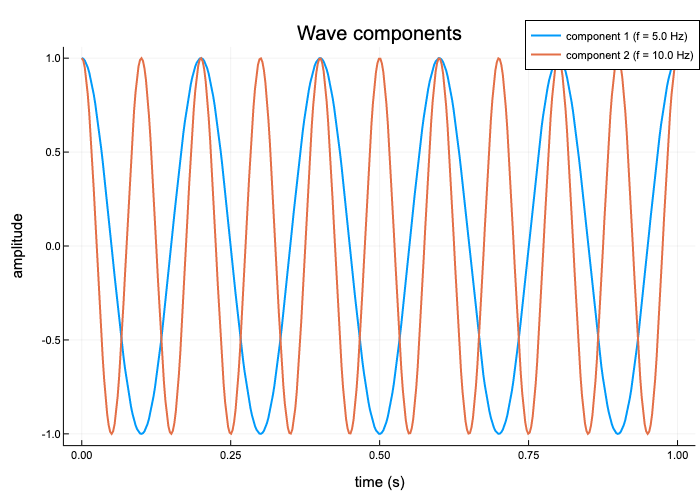

In [114]:
# Continuous and sampled time axes
interval = range(0.0, 1.0; length = 400)

# List some pairs of (frequency (Hz), amplitude, x-shift)
params = [ (5.0, 1.0, 0.0), (10.0, 0.5, 0.4) ]

# Linear combination of cosines evaluated at time t (scalar or vector).
wave_components(t) = [ cos.(2π .* params[k][1] .* (t .- params[k][3])) for k in eachindex(params) ]
# Plot each component with a different color
p = plot()
for (i, w) in enumerate(wave_components(interval))
    plot!(interval, w,
          lw = 2,
          color = i,
          label = "component $(i) (f = $(params[i][1]) Hz)")
end
plot!(xlabel = "time (s)", ylabel = "amplitude",
      title = "Wave components",
      legend = :topright)


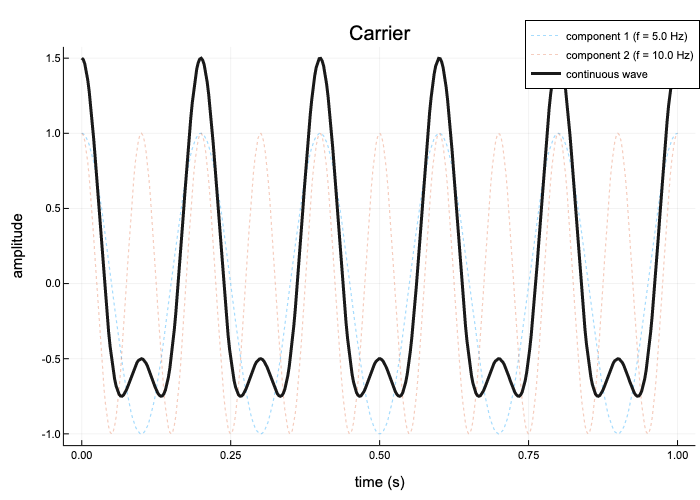

In [115]:

wave_combo(t) = sum(params[k][2] .* cos.(2π .* params[k][1] .* (t .- params[k][3])) for k in eachindex(params))

p = plot()
for (i, w) in enumerate(wave_components(interval))
    plot!(interval, w,
          lw = 1.2,
          ls = :dot,
          alpha = 0.35,
          color = i,
          label = "component $(i) (f = $(params[i][1]) Hz)")
end
plot!(interval, wave_combo(interval),
     lw = 3,
     ls = :solid,
     alpha = 0.9,
     color = :black,
     xlabel = "time (s)",
     ylabel = "amplitude",
     label = "continuous wave",
     title = "Carrier")

Now make multiply by a dampening envelope.


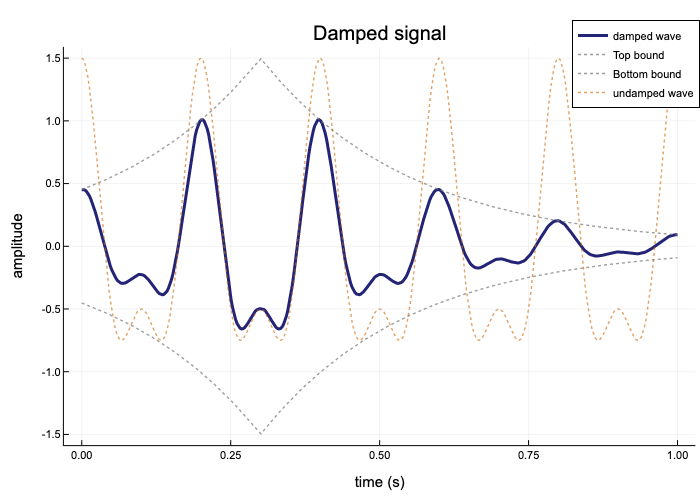

In [116]:
# Multiply the carrier by a damping envelope and plot
interval = range(0.0, 1.0; length = 400)

alpha = 4.0
t_peak = 0.30
envelope(t) = exp.(-alpha .* abs.(t .- t_peak))

wave_damped = envelope(interval) .* wave_combo(interval)
A_bound = sum(abs, getindex.(params, 2))

plot(interval, wave_damped,
    lw = 3,
    color = :midnightblue,
    alpha = 0.95,
    xlabel = "time (s)",
    ylabel = "amplitude",
    label = "damped wave",
    title = "Damped signal")
plot!(interval, A_bound .* envelope(interval),
      ls = :dot,
      lw = 1.4,
      color = :gray50,
      alpha = 0.75,
      label = "Top bound")
plot!(interval, -A_bound .* envelope(interval),
      ls = :dot,
      lw = 1.4,
      color = :gray50,
      alpha = 0.75,
      label = "Bottom bound")

plot!(interval, wave_combo(interval),
     lw = 1.4,
     ls = :dot,
     color = :darkorange3,
     alpha = 0.6,
     label = "undamped wave",
     legend = :topright)

Now sample some points to "discretize" the wave.  Notice here we may be limited by resolution to choose unfortunate positions.

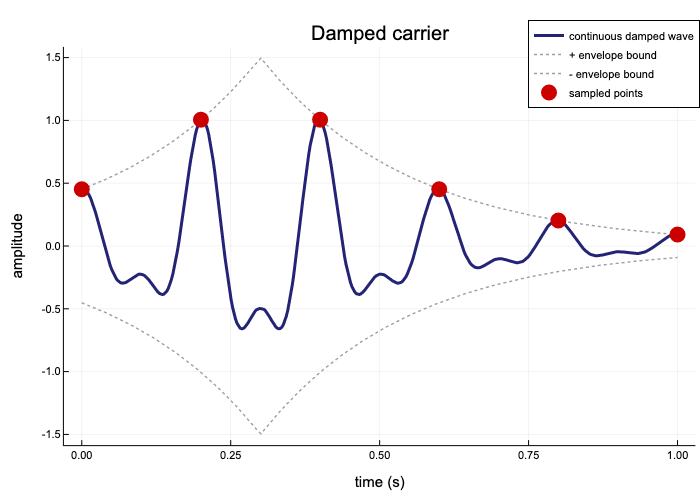

In [117]:
t_samples = range(0.0, 1.0; length = 6)

# Envelope that rises to a peak time and then decays.
alpha = 4.0          # damping strength in 1/seconds
t_peak = 0.30        # seconds
envelope(t) = exp.(-alpha .* abs.(t .- t_peak))

wave_u = envelope(interval) .* wave_combo(interval)
wave_s = envelope(t_samples) .* wave_combo(t_samples)

# For carrier(t)=sum a_k cos(...), a bound is sum(|a_k|).
A_bound = sum(abs, getindex.(params, 2))

plot(interval, wave_u,
     lw = 3,
     color = :midnightblue,
     alpha = 0.95,
     xlabel = "time (s)",
     ylabel = "amplitude",
     label = "continuous damped wave",
     title = "Damped carrier")
plot!(interval, A_bound .* envelope(interval),
      ls = :dot,
      lw = 1.4,
      color = :gray50,
      alpha = 0.75,
      label = "+ envelope bound")
plot!(interval, -A_bound .* envelope(interval),
      ls = :dot,
      lw = 1.4,
      color = :gray50,
      alpha = 0.75,
      label = "- envelope bound")
scatter!(t_samples, wave_s,
         ms = 8,
         color = :red3,
         markerstrokewidth = 0,
         label = "sampled points",
         legend = :topright)

## 2.2 A multi-mode damped oscillator




The goal is to show exactly how a dense `6×6×6` tensor can arise from a small number of damped oscillatory components (the same modeling idea used later), without hiding construction details in helper functions.

We choose 3 components with distinct frequencies on each axis (non-degenerate frequency triples), add component-specific damping and phase, then sum them over all `(i,j,k)` samples.  Finally, we add a small amount of complex Gaussian noise.

Two $f_x$ frequencies are only `0.08` apart.  Since one FFT bin at length 6 is `1/6 ≈ 0.167` cycles/sample, this pair is sub-bin separated, so a short FFT should blur them.

Below, the notebook uses the native Dleto steps directly: `nondeg`, then `der`, then `stratify`.  No `dleto_components` wrapper is used.

One subtle point is that `stratify` does **not** take the raw tensor by itself.  It takes a nondegenerate core `Δ` together with a chosen derivation triple `δ`.  So the old wrapper was mainly hiding the choice of `δ`, not replacing `stratify` with something fundamentally different.

In [118]:
n = 6
# Frequencies 
f_x = [0.08, 0.16, 0.37]
f_y = [0.11, 0.28, 0.41]
f_z = [0.09, 0.26, 0.44]

amps   = [1.00, 0.85, 0.70]
dampx  = [0.04, 0.06, 0.03]
dampy  = [0.03, 0.05, 0.04]
dampz  = [0.05, 0.04, 0.06]
phases = [0.00, 0.70, -0.45]

# Dense, non-degenerate 6x6x6 tensor from 3 damped oscillatory components.
Γ_synth = zeros(ComplexF64, n, n, n)
for i in 0:n-1, j in 0:n-1, k in 0:n-1
    s = 0.0 + 0.0im
    for m in eachindex(amps)
        sx = exp((-dampx[m] + 2pi * im * f_x[m]) * i)
        sy = exp((-dampy[m] + 2pi * im * f_y[m]) * j)
        sz = exp((-dampz[m] + 2pi * im * f_z[m]) * k)
        s += amps[m] * exp(im * phases[m]) * sx * sy * sz
    end
    Γ_synth[i + 1, j + 1, k + 1] = s
end

# Add light complex Gaussian noise to avoid exact algebraic structure.
Random.seed!(1)
σ = norm(Γ_synth) / sqrt(length(Γ_synth)) * 10.0^(-35 / 20)
Γ_synth .+= (σ / sqrt(2)) .* (randn(size(Γ_synth)) .+ im .* randn(size(Γ_synth)))


6×6×6 Array{ComplexF64, 3}:
[:, :, 1] =
    2.28128+0.228011im  -0.231957+1.71131im    …    -0.908175-0.377825im
   0.535068+1.90956im   -0.535744-0.0302346im        -1.19535-0.673335im
  -0.521918+0.535683im   0.235486+0.496406im      -0.00600721-1.82957im
  0.0815027+0.665307im  -0.647761+0.422283im          1.17047-0.46937im
  -0.862839+0.436968im   0.126876-0.0721111im        0.284151+0.0249337im
 -0.0424303-0.442842im  -0.367811+1.04794im    …     0.712448-0.204385im

[:, :, 2] =
  -0.21284+1.59332im     -0.047998-0.362855im  …  -0.895303-1.00349im
   -0.3463+0.00929438im   0.476887+0.675134im      0.493074-1.51783im
  0.210565+0.596257im    -0.439621+0.468573im      0.969266+0.0262964im
 -0.594691+0.263307im      0.10851+0.375217im     0.0434879-0.041869im
  0.288932+0.0111516im   -0.972929+1.06742im       0.651661-0.204784im
 -0.371516+1.15253im      -1.53123-0.669225im  …   0.178817+0.437941im

[:, :, 3] =
 0.0710847-0.340784im   0.536069+1.04297im   …    0.80809-1.06046im
  0.

In [119]:

println("Toy record size: ", size(Γ_synth), "; FFT bin = ", round(1 / n; digits = 3), " cycles/sample")
for (axis_name, axis_no, truth) in (("x", 1, f_x), ("y", 2, f_y), ("z", 3, f_z))
    println("FFT along $axis_name finds ", fft_peaks_1d(Γ_synth, axis_no), " ; truth = ", truth)
end

Γtoy_norm = Γ_synth / norm(Γ_synth)
fr_toy = [Index(size(Γtoy_norm, a), ("a", "b", "c")[a]) for a in 1:3]
Γtoy_it = ITensor(Γtoy_norm, fr_toy...)
Δtoy_it, Etoy = nondeg(Γtoy_it; tol = 0.05)
ch_toy = UniversalChisel(length(inds(Δtoy_it)))
Ωtoy = IndTransverseOps(collect(inds(Δtoy_it)), UniversalOp())
ders_toy = der(Ωtoy, ch_toy, Δtoy_it; nd = 6, tol = 0.15)

best_toy = nothing
for _ in 1:8
    coefs = randn(length(ders_toy))
    δtoy = [sum(coefs[j] * ders_toy[j][a] for j in eachindex(ders_toy)) for a in 1:3]
    St_try = stratify(Δtoy_it, δtoy)
    Σ_try = Array(St_try.Σ, inds(St_try.Σ)...)
    nz_try = count(x -> abs(x) > 0.1 * maximum(abs, Σ_try), Σ_try)
    if best_toy === nothing || nz_try < best_toy.nonzeros
        best_toy = (; nonzeros = nz_try, St = St_try)
    end
end
St_toy = best_toy.St

Etoy_m = Matrix{ComplexF64}[]
Xtoy_m = Matrix{ComplexF64}[]
e2_toy = Index[]
for a in 1:3
    E = only(filter(t -> hasind(t, fr_toy[a]), Etoy))
    e2 = only(filter(i -> i != fr_toy[a], inds(E)))
    X = only(filter(t -> hasind(t, e2), St_toy.Xs))
    x2 = only(filter(i -> i != e2, inds(X)))
    push!(Etoy_m, Array(E, fr_toy[a], e2))
    push!(Xtoy_m, Array(X, e2, x2))
    push!(e2_toy, e2)
end

Δtoy = Array(Δtoy_it, inds(Δtoy_it)...)
Σtoy = Array(St_toy.Σ, e2_toy...)
top_toy = CartesianIndices(Σtoy)[partialsortperm(vec(abs2.(Σtoy)), 1:3; rev = true)]
factors_toy = [[(conj(Etoy_m[a]) * transpose(inv(Xtoy_m[a])))[:, Tuple(ci)[a]] for a in 1:3] for ci in top_toy]
nonzeros_toy = count(x -> abs(x) > 0.1 * maximum(abs, Σtoy), Σtoy)
record_nonzeros_toy = count(x -> abs(x) > 0.1 * maximum(abs, Γ_synth), Γ_synth)

println("nondeg core size: ", size(Δtoy), "   (from original ", size(Γ_synth), ")")
println("strata size:      ", size(Σtoy))
println("derivation basis size: ", length(ders_toy))
println("strata nonzeros ", nonzeros_toy, " of ", length(Σtoy),
        "   (record: ", record_nonzeros_toy, " of ", length(Γ_synth), ")")
println("recovered frequencies (cycles/sample):")
for f in factors_toy
    @printf("   x %.4f   y %.4f   z %.4f\n", frequency(f[1]), frequency(f[2]), frequency(f[3]))
end
println("true triples: ", collect(zip(f_x, f_y, f_z)))

Toy record size: (6, 6, 6); FFT bin = 0.167 cycles/sample
FFT along x finds [0.16666666666666666] ; truth = [0.08, 0.16, 0.37]
FFT along y finds [0.16666666666666666] ; truth = [0.11, 0.28, 0.41]
FFT along z finds [0.16666666666666666, 0.5] ; truth = [0.09, 0.26, 0.44]
Using SVDSolver...
Converting LinearMap to Matrix for SVD...
nondeg core size: (3, 3, 3)   (from original (6, 6, 6))
strata size:      (3, 3, 3)
derivation basis size: 6
strata nonzeros 3 of 27   (record: 209 of 216)
recovered frequencies (cycles/sample):
   x 0.0800   y 0.1102   z 0.0899
   x 0.3699   y 0.4101   z 0.4399
   x 0.1598   y 0.2806   z 0.2604
true triples: [(0.08, 0.11, 0.09), (0.16, 0.28, 0.26), (0.37, 0.41, 0.44)]


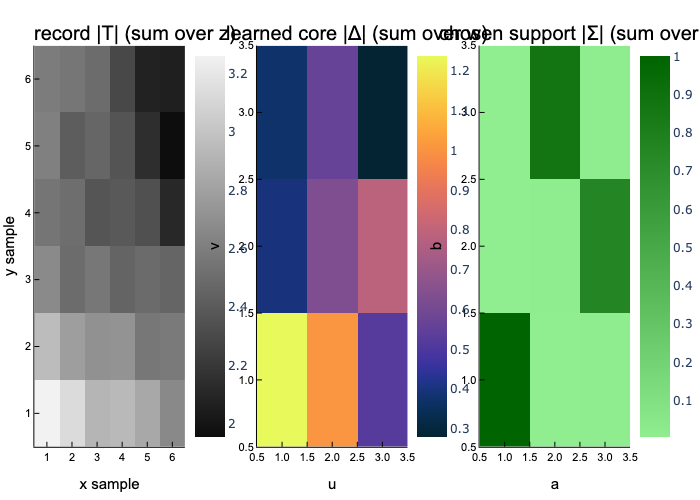

In [120]:
# Robust fallback visualization (avoids plot_tensor InexactError)
Arec = abs.(Γ_synth) ./ maximum(abs, Γ_synth)
Acore = abs.(Δtoy) ./ maximum(abs, Δtoy)
Astr = abs.(Σtoy) ./ maximum(abs, Σtoy)

p1 = heatmap(sum(Arec, dims = 3)[:, :, 1];
    xlabel = "x sample", ylabel = "y sample", title = "record |T| (sum over z)", color = :grays)
p2 = heatmap(sum(Acore, dims = 3)[:, :, 1];
    xlabel = "u", ylabel = "v", title = "learned core |Δ| (sum over w)", color = :thermal)
p3 = heatmap(sum(Astr, dims = 3)[:, :, 1];
    xlabel = "a", ylabel = "b", title = "chosen support |Σ| (sum over c)", color = :greens)
plot(p1, p2, p3; layout = (1, 3), size = (1500, 420))

**What the warm-up shows.** We started from a dense `6×6×6` tensor built directly from three distinct damped frequency triples, not from a pre-chiseled sparse object.

Dleto first moves the data into learned coordinates and isolates an informative core.  This is a coordinate-learning step for universal chisels, not a requirement that the input be degenerate.

Then `stratify` makes the representation much simpler, concentrating mass near about one dominant entry per component.

In plain language: the raw sample grid looks spread out; in learned coordinates the same signal becomes compact and structured.

This does **not** prove the measured HNCO case will always work.  It only demonstrates the mechanism in a tiny setting where ground truth is known.

## 3. The measured problem: one 3D HNCO band of a protein

An HNCO is a 3D protein NMR experiment.  For each cross peak, the three axes record:

- amide `1H`,
- amide `15N`,
- the preceding carbonyl `13C'`.

Here we use a **single narrow `1H` band** from a real HNCO of mouse thiamine triphosphatase.  The prepared sub-band contains:

- two strong peaks whose `13C'` shifts differ by `0.93 ppm`,
- a weaker third peak inside the same band,
- an edge peak near `13C' = -1.24 ppm`.

The full `13C'` record has 32 increments, but the key challenge is the shorter case with only 16 increments.  At 16 increments, the `13C'` FFT bin is `1.24 ppm`, which is **wider than the 0.93 ppm separation** of the two strong peaks.  So the FFT grid itself is too coarse to cleanly separate them.

Unlike the earlier HSQC example, no mode is manufactured here: the tensor is the acquired three-way record `(15N, 13C', 1H)`.


In [121]:
h = h5open("harmonic-retrieval/data/bmr15063_hnco_band_3.56-3.68ppm.h5", "r")
H = permutedims(read(h["fid"]), (3, 2, 1))
refs3 = permutedims(read(h["ref_peaks"]))
swN, swC, swH, obsN, obsC, obsH, fcH = (read_attribute(h, k) for k in ("swN", "swC", "swH", "obsN", "obsC", "obsH", "fcH"))
close(h)

strong3 = refs3[refs3[:, 4] .> 100, :]
println("record (15N, 13C', 1H) = ", size(H))
println("FFT bins at full length: 15N ", round(swN / size(H, 1) / obsN; digits = 2),
        " ppm, 13C' ", round(swC / size(H, 2) / obsC; digits = 2), " ppm")
println("strong reference peaks (ppm from carrier; last column = height / noise floor):")
for s in eachrow(strong3)
    @printf("   15N %6.2f   13C' %6.2f   1H %6.3f   (height %.0f × floor)\n",
            s[1] / obsN, s[2] / obsC, s[3] / obsH, s[4])
end

record (15N, 13C', 1H) = (40, 32, 7)
FFT bins at full length: 15N 0.86 ppm, 13C' 0.62 ppm
strong reference peaks (ppm from carrier; last column = height / noise floor):
   15N   7.35   13C'   0.93   1H  3.662   (height 933 × floor)
   15N  -7.35   13C'   0.00   1H  3.603   (height 903 × floor)
   15N   1.30   13C'   2.18   1H  3.642   (height 171 × floor)


In [122]:
# Standard FFT peak picker baseline on the 13C' axis.
function fft_peak_picker_c13(T::AbstractArray{<:Number,3}, swC, obsC; k::Int = 3, rel::Real = 0.20)
    F = fft(T, 2)
    profile = vec(sum(abs.(F), dims = (1, 3)))
    n = length(profile)

    # Circular local maxima above a relative threshold.
    maxima = [i for i in 1:n if profile[i] >= profile[mod1(i - 1, n)] &&
                                profile[i] >= profile[mod1(i + 1, n)] &&
                                profile[i] >= rel * maximum(profile)]
    order = sort(maxima; by = i -> profile[i], rev = true)
    keep = order[1:min(k, length(order))]

    cyc = [((i - 1) <= n ÷ 2) ? (i - 1) / n : (i - 1 - n) / n for i in keep]
    ppm = [f * swC / obsC for f in cyc]
    axis_cyc = [((i - 1) <= n ÷ 2) ? (i - 1) / n : (i - 1 - n) / n for i in 1:n]
    axis_ppm = [f * swC / obsC for f in axis_cyc]
    return (; bins = keep, cyc, ppm, heights = profile[keep], profile, axis_ppm)
end

fft_peak_picker_c13 (generic function with 1 method)

## 4. Full `13C'` length first: 32 increments

This is the easier of the two measured runs.  It serves as a baseline: if the method cannot recover the main peaks here, the short-record case would not be believable.

We keep `M = 3` components because, at this tolerance, `nondeg` reliably keeps the two strong peaks and the edge peak.

In [123]:
Random.seed!(1)
T32 = H[:, 1:32, :]
T32_norm = T32 / norm(T32)
fr32 = [Index(size(T32_norm, a), ("a", "b", "c")[a]) for a in 1:3]
Γ32 = ITensor(T32_norm, fr32...)
Δ32_it, E32 = nondeg(Γ32; tol = 0.2)
ch32 = UniversalChisel(length(inds(Δ32_it)))
Ω32 = IndTransverseOps(collect(inds(Δ32_it)), UniversalOp())
ders32 = der(Ω32, ch32, Δ32_it; nd = 6, tol = 0.3)

best32 = nothing
for _ in 1:10
    coefs = randn(length(ders32))
    δ32 = [sum(coefs[j] * ders32[j][a] for j in eachindex(ders32)) for a in 1:3]
    St_try = stratify(Δ32_it, δ32)
    Σ_try = Array(St_try.Σ, inds(St_try.Σ)...)
    nz_try = count(x -> abs(x) > 0.1 * maximum(abs, Σ_try), Σ_try)
    if best32 === nothing || nz_try < best32.nonzeros
        best32 = (; nonzeros = nz_try, St = St_try)
    end
end
St32 = best32.St

E32_m = Matrix{ComplexF64}[]
X32_m = Matrix{ComplexF64}[]
e232 = Index[]
for a in 1:3
    E = only(filter(t -> hasind(t, fr32[a]), E32))
    e2 = only(filter(i -> i != fr32[a], inds(E)))
    X = only(filter(t -> hasind(t, e2), St32.Xs))
    x2 = only(filter(i -> i != e2, inds(X)))
    push!(E32_m, Array(E, fr32[a], e2))
    push!(X32_m, Array(X, e2, x2))
    push!(e232, e2)
end

Δ32 = Array(Δ32_it, inds(Δ32_it)...)
Σ32 = Array(St32.Σ, e232...)
nonzeros32 = count(x -> abs(x) > 0.1 * maximum(abs, Σ32), Σ32)
record_nonzeros32 = count(x -> abs(x) > 0.1 * maximum(abs, T32), T32)
top32 = CartesianIndices(Σ32)[partialsortperm(vec(abs2.(Σ32)), 1:3; rev = true)]
B32 = [conj(E32_m[a]) * transpose(inv(X32_m[a])) for a in 1:3]
factors32 = [[B32[a][:, Tuple(ci)[a]] for a in 1:3] for ci in top32]
support32 = sort([ci for ci in CartesianIndices(Σ32) if abs(Σ32[ci]) > 0.1 * maximum(abs, Σ32)];
                 by = ci -> abs2(Σ32[ci]), rev = true)
Tdleto32 = zeros(ComplexF64, size(T32)...)
for ci in support32
    f = [B32[a][:, Tuple(ci)[a]] for a in 1:3]
    Tdleto32 .+= Σ32[ci] .* reshape(f[1], length(f[1]), 1, 1) .*
                  reshape(f[2], 1, length(f[2]), 1) .*
                  reshape(f[3], 1, 1, length(f[3]))
end
F32_3d = abs.(fftshift(fft(T32)))
F32_3d ./= maximum(F32_3d)
w32 = abs.([Σ32[ci] for ci in top32])
perm32 = sortperm([frequency(f[2]) * swC / obsC for f in factors32])
c13_dleto32 = [frequency(factors32[i][2]) * swC / obsC for i in perm32]
w32 = w32[perm32]
fft32 = fft_peak_picker_c13(T32, swC, obsC; k = 3, rel = 0.20)

println("13C' increments: 32  (FFT bin ", round(swC / 32 / obsC; digits = 2), " ppm)")
println("core size ", size(Δ32), "; strata nonzeros ", nonzeros32, " of ", length(Σ32),
        "   (record: ", record_nonzeros32, " of ", length(T32), ")")
println("derivation basis size ", length(ders32))
println("Dleto recovered components (ppm from carrier):")
for f in factors32
    @printf("   15N %6.2f   13C' %6.2f   1H %6.3f ppm\n",
            frequency(f[1]) * swN / obsN,
            frequency(f[2]) * swC / obsC,
            (frequency(f[3]) * swH + fcH) / obsH)
end
println("FFT peak-picker baseline on 13C' axis (top bins):")
for j in eachindex(fft32.bins)
    @printf("   bin %2d   13C' %6.2f ppm   (relative height %.3f)\n",
            fft32.bins[j], fft32.ppm[j], fft32.heights[j] / maximum(fft32.profile))
end

Using SVDSolver...
Converting LinearMap to Matrix for SVD...
13C' increments: 32  (FFT bin 0.62 ppm)
core size (3, 3, 3); strata nonzeros 3 of 27   (record: 4469 of 8960)
derivation basis size 6
Dleto recovered components (ppm from carrier):
   15N   7.16   13C'   1.00   1H  3.652 ppm
   15N  -7.45   13C'  -0.08   1H  3.606 ppm
   15N   6.04   13C'  -1.22   1H  3.576 ppm
FFT peak-picker baseline on 13C' axis (top bins):
   bin  3   13C'   1.24 ppm   (relative height 1.000)
   bin  1   13C'   0.00 ppm   (relative height 0.976)
   bin 31   13C'  -1.24 ppm   (relative height 0.717)


At full `13C'` length, this notebook should recover the two strong carbonyl positions near `0.93 ppm` and `0.00 ppm`, plus the edge peak near `-1.24 ppm`, while reducing the tensor to only a few large strata entries.  That is the sanity check.

## 5. The actual challenge: only 16 `13C'` increments

Now we deliberately shorten the carbonyl dimension to 16 increments.

- FFT bin at 32 increments: `0.62 ppm`
- FFT bin at 16 increments: `1.24 ppm`
- separation of the two strong peaks: `0.93 ppm`

So the two peaks are only about **0.75 of one FFT bin apart** in the short record.  For an FFT-based reading, that is the hard case.

For both the 32- and 16-increment runs below, we print a direct comparison:
- Dleto recovered peak estimates,
- a standard FFT peak-picker baseline on the `13C'` axis.


In [124]:
Random.seed!(1)
T16 = H[:, 1:16, :]
T16_norm = T16 / norm(T16)
fr16 = [Index(size(T16_norm, a), ("a", "b", "c")[a]) for a in 1:3]
Γ16 = ITensor(T16_norm, fr16...)
Δ16_it, E16 = nondeg(Γ16; tol = 0.2)
ch16 = UniversalChisel(length(inds(Δ16_it)))
Ω16 = IndTransverseOps(collect(inds(Δ16_it)), UniversalOp())
ders16 = der(Ω16, ch16, Δ16_it; nd = 6, tol = 0.3)

best16 = nothing
for _ in 1:10
    coefs = randn(length(ders16))
    δ16 = [sum(coefs[j] * ders16[j][a] for j in eachindex(ders16)) for a in 1:3]
    St_try = stratify(Δ16_it, δ16)
    Σ_try = Array(St_try.Σ, inds(St_try.Σ)...)
    nz_try = count(x -> abs(x) > 0.1 * maximum(abs, Σ_try), Σ_try)
    if best16 === nothing || nz_try < best16.nonzeros
        best16 = (; nonzeros = nz_try, St = St_try)
    end
end
St16 = best16.St

E16_m = Matrix{ComplexF64}[]
X16_m = Matrix{ComplexF64}[]
e216 = Index[]
for a in 1:3
    E = only(filter(t -> hasind(t, fr16[a]), E16))
    e2 = only(filter(i -> i != fr16[a], inds(E)))
    X = only(filter(t -> hasind(t, e2), St16.Xs))
    x2 = only(filter(i -> i != e2, inds(X)))
    push!(E16_m, Array(E, fr16[a], e2))
    push!(X16_m, Array(X, e2, x2))
    push!(e216, e2)
end

Δ16 = Array(Δ16_it, inds(Δ16_it)...)
Σ16 = Array(St16.Σ, e216...)
nonzeros16 = count(x -> abs(x) > 0.1 * maximum(abs, Σ16), Σ16)
record_nonzeros16 = count(x -> abs(x) > 0.1 * maximum(abs, T16), T16)
top16 = CartesianIndices(Σ16)[partialsortperm(vec(abs2.(Σ16)), 1:3; rev = true)]
B16 = [conj(E16_m[a]) * transpose(inv(X16_m[a])) for a in 1:3]
factors16 = [[B16[a][:, Tuple(ci)[a]] for a in 1:3] for ci in top16]
support16 = sort([ci for ci in CartesianIndices(Σ16) if abs(Σ16[ci]) > 0.1 * maximum(abs, Σ16)];
                 by = ci -> abs2(Σ16[ci]), rev = true)
Tdleto16 = zeros(ComplexF64, size(T16)...)
for ci in support16
    f = [B16[a][:, Tuple(ci)[a]] for a in 1:3]
    Tdleto16 .+= Σ16[ci] .* reshape(f[1], length(f[1]), 1, 1) .*
                  reshape(f[2], 1, length(f[2]), 1) .*
                  reshape(f[3], 1, 1, length(f[3]))
end
F16_3d = abs.(fftshift(fft(T16)))
F16_3d ./= maximum(F16_3d)
w16 = abs.([Σ16[ci] for ci in top16])
perm16 = sortperm([frequency(f[2]) * swC / obsC for f in factors16])
c13_dleto16 = [frequency(factors16[i][2]) * swC / obsC for i in perm16]
w16 = w16[perm16]
fft16 = fft_peak_picker_c13(T16, swC, obsC; k = 3, rel = 0.20)

println("13C' increments: 16  (FFT bin ", round(swC / 16 / obsC; digits = 2), " ppm)")
println("core size ", size(Δ16), "; strata nonzeros ", nonzeros16, " of ", length(Σ16),
        "   (record: ", record_nonzeros16, " of ", length(T16), ")")
println("derivation basis size ", length(ders16))
println("Dleto recovered components (ppm from carrier):")
for f in factors16
    @printf("   15N %6.2f   13C' %6.2f   1H %6.3f ppm\n",
            frequency(f[1]) * swN / obsN,
            frequency(f[2]) * swC / obsC,
            (frequency(f[3]) * swH + fcH) / obsH)
end
println("FFT peak-picker baseline on 13C' axis (top bins):")
for j in eachindex(fft16.bins)
    @printf("   bin %2d   13C' %6.2f ppm   (relative height %.3f)\n",
            fft16.bins[j], fft16.ppm[j], fft16.heights[j] / maximum(fft16.profile))
end

Using SVDSolver...
Converting LinearMap to Matrix for SVD...
13C' increments: 16  (FFT bin 1.24 ppm)
core size (3, 3, 3); strata nonzeros 3 of 27   (record: 2290 of 4480)
derivation basis size 6
Dleto recovered components (ppm from carrier):
   15N   7.11   13C'   0.99   1H  3.652 ppm
   15N  -7.35   13C'  -0.11   1H  3.605 ppm
   15N   6.09   13C'  -1.26   1H  3.575 ppm
FFT peak-picker baseline on 13C' axis (top bins):
   bin  2   13C'   1.24 ppm   (relative height 1.000)


## 6. Peak-merging progression on one number line

To see **where peaks merge** as the `13C'` record gets shorter, the next plot strips things down to only the selected peak positions.  Each row is one record length (`32`, `24`, `16`, `12`, `8` increments), drawn on the same `13C'` number line.

- red points = FFT peak-picker bins,
- blue points = Dleto-selected components.

This lets the eye track when the FFT picks collapse onto the same coarse bin while Dleto still places separate points.


Using SVDSolver...
Converting LinearMap to Matrix for SVD...
Using SVDSolver...
Converting LinearMap to Matrix for SVD...
Using SVDSolver...
Converting LinearMap to Matrix for SVD...


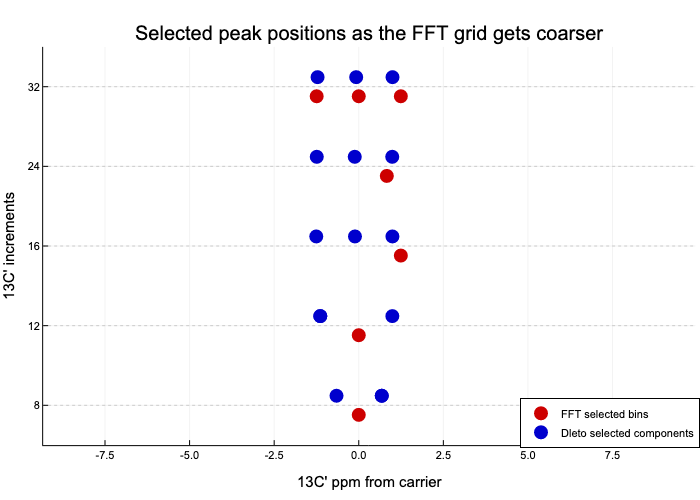

In [125]:
function hnco_progression_case(N; M = 3, tol_nd = 0.2, tol_der = 0.3, ntries = 10, seed = 1)
    Random.seed!(seed)
    T = H[:, 1:N, :]
    T_norm = T / norm(T)
    fr = [Index(size(T_norm, a), ("a", "b", "c")[a]) for a in 1:3]
    Γ = ITensor(T_norm, fr...)
    Δ_it, E = nondeg(Γ; tol = tol_nd)
    ch = UniversalChisel(length(inds(Δ_it)))
    Ω = IndTransverseOps(collect(inds(Δ_it)), UniversalOp())
    ders = der(Ω, ch, Δ_it; nd = 6, tol = tol_der)

    best = nothing
    for _ in 1:ntries
        coefs = randn(length(ders))
        δ = [sum(coefs[j] * ders[j][a] for j in eachindex(ders)) for a in 1:3]
        St_try = stratify(Δ_it, δ)
        Σ_try = Array(St_try.Σ, inds(St_try.Σ)...)
        nz_try = count(x -> abs(x) > 0.1 * maximum(abs, Σ_try), Σ_try)
        if best === nothing || nz_try < best.nonzeros
            best = (; nonzeros = nz_try, St = St_try)
        end
    end
    St = best.St

    E_m = Matrix{ComplexF64}[]
    X_m = Matrix{ComplexF64}[]
    e2s = Index[]
    for a in 1:3
        Ea = only(filter(t -> hasind(t, fr[a]), E))
        e2 = only(filter(i -> i != fr[a], inds(Ea)))
        Xa = only(filter(t -> hasind(t, e2), St.Xs))
        x2 = only(filter(i -> i != e2, inds(Xa)))
        push!(E_m, Array(Ea, fr[a], e2))
        push!(X_m, Array(Xa, e2, x2))
        push!(e2s, e2)
    end

    Σ = Array(St.Σ, e2s...)
    top = CartesianIndices(Σ)[partialsortperm(vec(abs2.(Σ)), 1:M; rev = true)]
    B = [conj(E_m[a]) * transpose(inv(X_m[a])) for a in 1:3]
    factors = [[B[a][:, Tuple(ci)[a]] for a in 1:3] for ci in top]
    w = abs.([Σ[ci] for ci in top])
    perm = sortperm([frequency(f[2]) * swC / obsC for f in factors])
    c13_dleto = [frequency(factors[i][2]) * swC / obsC for i in perm]
    w = w[perm]
    fftres = fft_peak_picker_c13(T, swC, obsC; k = M, rel = 0.20)
    return (; N, c13_dleto, w, fftres)
end

progression_cases = Dict(
    32 => (; N = 32, c13_dleto = c13_dleto32, w = w32, fftres = fft32),
    16 => (; N = 16, c13_dleto = c13_dleto16, w = w16, fftres = fft16),
)
for N in (24, 12, 8)
    progression_cases[N] = hnco_progression_case(N)
end

function peak_progression_plot(cases, counts)
    rows = 1:length(counts)
    p = plot(;
        xlabel = "13C' ppm from carrier",
        ylabel = "13C' increments",
        yticks = (collect(rows), string.(counts)),
        yflip = true,
        ylim = (0.5, length(counts) + 0.5),
        xlims = (minimum(fft32.axis_ppm), maximum(fft32.axis_ppm)),
        legend = :bottomright,
        title = "Selected peak positions as the FFT grid gets coarser"
    )
    for (row, N) in enumerate(counts)
        hline!(p, [row]; color = :gray80, lw = 1, linestyle = :dot, label = "")
        case = cases[N]
        scatter!(p, case.fftres.ppm, fill(row + 0.12, length(case.fftres.ppm));
                 color = :red3, ms = 7, markerstrokewidth = 0,
                 label = row == 1 ? "FFT selected bins" : "")
        scatter!(p, case.c13_dleto, fill(row - 0.12, length(case.c13_dleto));
                 color = :blue3, ms = 7, markerstrokewidth = 0,
                 label = row == 1 ? "Dleto selected components" : "")
    end
    return p
end

peak_progression_plot(progression_cases, [32, 24, 16, 12, 8])

┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257
┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257


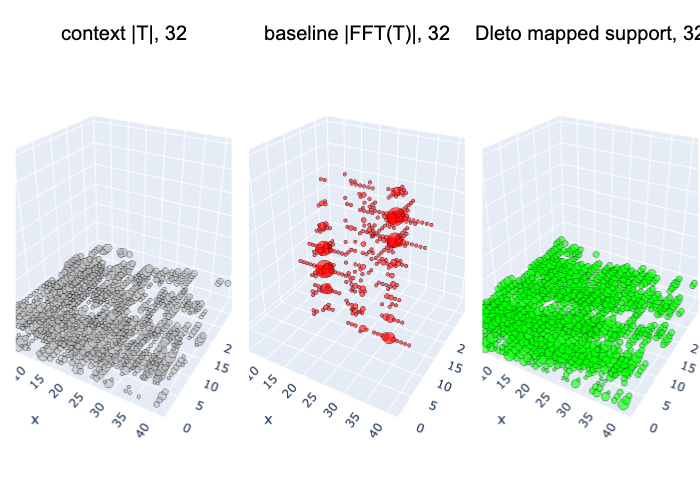

In [129]:
# Three-tensor view with OpenDleto plot_tensor (32 increments)
A32 = abs.(T32) ./ maximum(abs, T32)
F32 = abs.(F32_3d) ./ maximum(abs, F32_3d)
D32 = abs.(Tdleto32) ./ maximum(abs, Tdleto32)

thr = 0.2
p1 = plot_tensor(A32, thr;
    title = "context |T|, 32", xlabel = "15N", ylabel = "13C'", zlabel = "1H", color = :gray45)
p2 = plot_tensor(F32, thr;
    title = "baseline |FFT(T)|, 32", xlabel = "15N freq", ylabel = "13C' freq", zlabel = "1H freq", color = :red3)
p3 = plot_tensor(D32, thr;
    title = "Dleto mapped support, 32", xlabel = "15N", ylabel = "13C'", zlabel = "1H", color = :green3)

plot(p1, p2, p3; layout = (1, 3), size = (1650, 520))

**One direct stratification picture.** Before pulling the sparse representation back onto the original `(15N, 13C', 1H)` grid, it helps to see the actual stratified tensor `Σ` itself.  The two panels below show the measured HNCO stratification directly in learned coordinates for `32` and `16` increments.


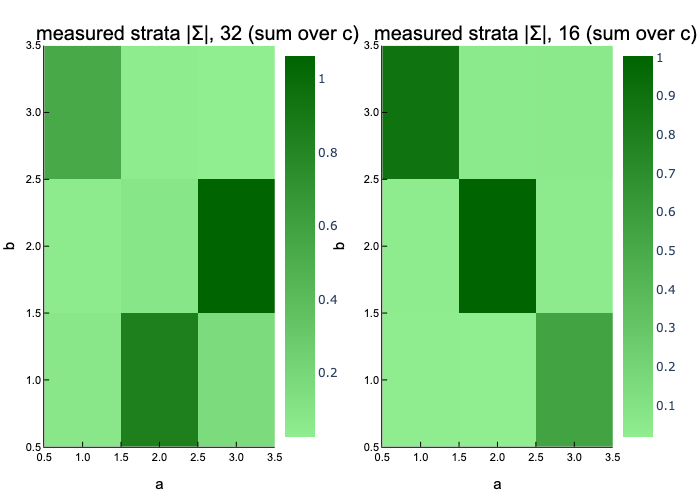

In [127]:
# Direct view of measured strata in learned coordinates (2D projections)
S32 = abs.(Σ32) ./ maximum(abs, Σ32)
S16 = abs.(Σ16) ./ maximum(abs, Σ16)

p1 = heatmap(sum(S32, dims = 3)[:, :, 1];
    title = "measured strata |Σ|, 32 (sum over c)", xlabel = "a", ylabel = "b", color = :greens)
p2 = heatmap(sum(S16, dims = 3)[:, :, 1];
    title = "measured strata |Σ|, 16 (sum over c)", xlabel = "a", ylabel = "b", color = :greens)

plot(p1, p2; layout = (1, 2), size = (1100, 420))

## 8. 3D FFT and Dleto views

The 3D panels above compare, for both `32` and `16` `13C'` increments, the original record, the full 3D FFT magnitude, and a sparse Dleto reconstruction mapped back onto the original `(15N, 13C', 1H)` grid by composing the nondegenerate and stratifying transforms.  So the Dleto picture is no longer shown only in compressed `Σ` coordinates.  The muted gray and red clouds are context and FFT baseline; the vivid green cloud is the sparse Dleto support we actually keep.

The two profile plots below still show the simple FFT baseline along the `13C'` axis.  The dotted gray staircase is the FFT magnitude profile, the red dots are the FFT local maxima, the faint blue curve is a smoothed sparse profile built from the Dleto-recovered `13C'` components, and the blue dots are the Dleto-selected `13C'` components.


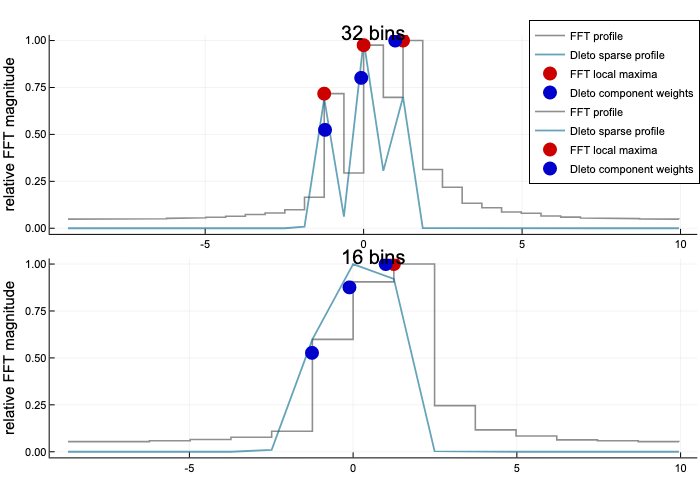

In [128]:
function dleto_sparse_profile(axis_ppm, c_dleto, weights)
    step = minimum(diff(sort(axis_ppm)))
    width = 0.35 * step
    w = weights ./ maximum(weights)
    prof = zeros(length(axis_ppm))
    for (μ, a) in zip(c_dleto, w)
        prof .+= a .* exp.(-0.5 .* ((axis_ppm .- μ) ./ width) .^ 2)
    end
    return prof ./ maximum(prof)
end

function fft_profile_plot(fftres, c_dleto, weights; title)
    order = sortperm(fftres.axis_ppm)
    x = fftres.axis_ppm[order]
    y = fftres.profile[order] ./ maximum(fftres.profile)
    y_dleto = dleto_sparse_profile(x, c_dleto, weights)

    p = plot(x, y; seriestype = :steppost, lw = 1.6, color = :gray45, linestyle = :solid, alpha = 0.8,
              ylabel = "relative FFT magnitude",
             title = title, label = "FFT profile", legend = :topright)
    plot!(p, x, y_dleto; lw = 1.8, color = :deepskyblue4, linestyle = :solid, alpha = 0.6, label = "Dleto sparse profile")
    scatter!(p, fftres.ppm, fftres.heights ./ maximum(fftres.profile);
             color = :red3, ms = 7, markerstrokewidth = 0, label = "FFT local maxima")
    scatter!(p, c_dleto, weights ./ maximum(weights); color = :blue3, ms = 7, markerstrokewidth = 0, label = "Dleto component weights")
    return p
end

plot(
    fft_profile_plot(fft32, c13_dleto32, w32; title = "32 bins"),
    fft_profile_plot(fft16, c13_dleto16, w16; title = "16 bins");
    layout = (2, 1), size = (1000, 700))

## 9. What the FFT vs Dleto comparison means

This notebook now includes a direct, printed baseline comparison, a peak-merging progression plot across `32/24/16/12/8` increments, 3D FFT/Dleto views on the original grid, and an FFT-profile plot in the detailed `32`- and `16`-increment runs:

- **Dleto** recovered components (with `15N`, `13C'`, `1H` coordinates),
- a **standard FFT peak-picker** on the `13C'` axis (top local maxima from the FFT magnitude profile).

### What is being compared

The FFT baseline is intentionally simple and standard:

- compute FFT along `13C'`,
- sum magnitude over `15N` and `1H`,
- pick top local maxima bins above a relative threshold.

So this baseline reports what a fixed-bin FFT readout sees in `13C'` for the same records.

### What the result says in this lab

- At **32 increments** (`13C'` bin about `0.62 ppm`), both methods identify the main carbonyl regions.
- At **16 increments** (`13C'` bin about `1.24 ppm`), the FFT peak-picker is forced onto noticeably coarser bins, while Dleto still reports separated components near the expected strong-peak region and edge region.

This is the core claim of the lab: in the short-record regime where FFT bins are too coarse, Dleto can still recover separated structure under these sparsity/model assumptions.

### Scope and limits of this comparison

This is a fair **baseline comparison**, not an exhaustive benchmark:

- FFT here is a direct peak-picker baseline, not a full parametric fit,
- Dleto uses a structured model (nondegenerate + stratified coordinates),
- conclusions are for this band and these settings, not a universal super-resolution guarantee.


## 10. Scientific take-away, stated carefully

What this notebook **does show**:

- On this measured protein HNCO example, Dleto can retain separated structure after the FFT grid has become too coarse to give a clean reading.
- In this example, the representation becomes much sparser after `nondeg + stratify`, which is the structural signal Dleto is designed to exploit.

What this notebook **does not show**:

- It is not unlimited super-resolution.  At sufficiently short records the recovered pair will also collapse here.
- It does not recover every weak peak in a band, and it depends on the data really being close to a small sum of damped exponentials.
- It does not claim that FFT is "wrong".  FFT is solving a different problem: projection onto a fixed frequency grid.  Dleto is attempting to learn a more suitable basis when the data really is close to a small sum of exponentials.

For a chemistry-minded reader: the practical message is not that Dleto replaces normal NMR processing, but that **short indirect dimensions can still contain more usable structural information than the FFT grid alone reveals**, at least in sparse, well-behaved sub-bands like the HNCO region shown here.